# JLPT weak labels — Phase 0 EDA

**Job: decide the two open thresholds `τ_oov` and `X`, and gate label quality.** Not exploration
for its own sake (spec §7). This labeling function *ships* in v1 (no BERT downstream to clean its
noise), so the OOV-gate and the spot-check here are **product criteria**.

- `τ_oov` — OOV rate above which the sentence is outside the JLPT frame → **ABSTAIN**.
- `X` — cumulative coverage; the sentence level is the lowest `L` covering ≥ `X` of in-frame tokens.

The ETL stored *ingredients* (`oov_rate`, per-level token counts), so both thresholds are swept
here without re-tokenizing the 249k-sentence corpus.

*Corpus: Japanese sentences from [Tatoeba](https://tatoeba.org), CC-BY 2.0 FR. JLPT vocab lists
from [Tanos](https://www.tanos.co.uk/jlpt/) (Jonathan Waller). Example sentences shown below are
illustrative, under attribution.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/jlpt/weak_labels.parquet")
LEVELS = ["n5", "n4", "n3", "n2", "n1"]
COUNTS = df[[f"{l}_count" for l in LEVELS]].to_numpy()
frame = df["n_in_frame"].to_numpy()
oov = df["oov_rate"].to_numpy()
has_frame = frame > 0
print(f"{len(df):,} sentences | {has_frame.sum():,} with in-frame tokens "
      f"| {(df.n_content == 0).sum():,} with no content words")

248,802 sentences | 242,859 with in-frame tokens | 417 with no content words


In [2]:
def weak_label(tau_oov, X):
    """Vectorized twin of labeling.LabelResult.weak_label (the tested scalar source)."""
    out = np.full(len(df), -1)
    ok = has_frame & (oov <= tau_oov)
    cum = np.zeros(len(df))
    assigned = ~ok
    for i in range(5):
        cum += COUNTS[:, i]
        hit = ok & ~assigned & (cum / np.where(frame == 0, 1, frame) >= X)
        out[hit] = i
        assigned |= hit
    out[ok & ~assigned] = 4
    return out

## 1. OOV-rate distribution → `τ_oov`

Read the gate off the distribution, don't guess it.

OOV-rate percentiles:
  p10: 0.000
  p25: 0.000
  p50: 0.200
  p60: 0.250
  p70: 0.333
  p75: 0.333
  p80: 0.417
  p85: 0.500
  p90: 0.500
  p95: 0.667
  p99: 1.000


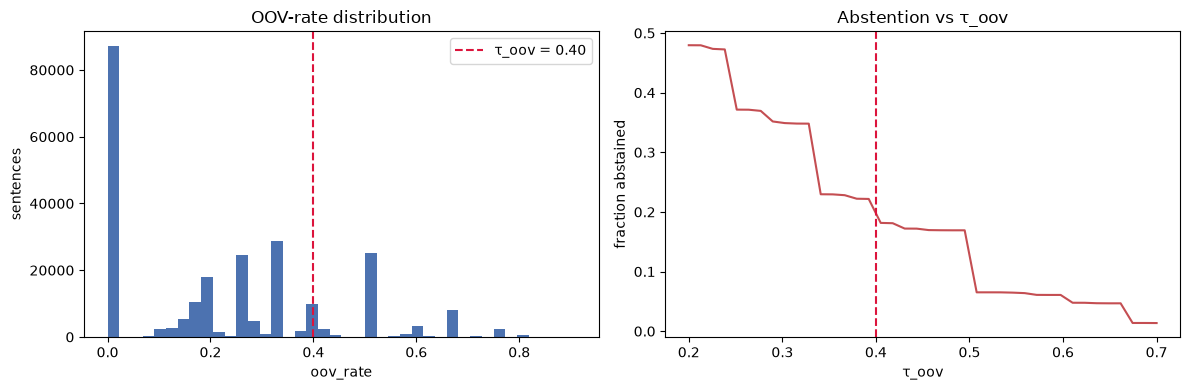

In [3]:
pct = [10, 25, 50, 60, 70, 75, 80, 85, 90, 95, 99]
print("OOV-rate percentiles:")
for p in pct:
    print(f"  p{p:>2}: {np.percentile(oov, p):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(oov[has_frame], bins=40, color="#4C72B0")
ax[0].axvline(0.40, color="crimson", ls="--", label="τ_oov = 0.40")
ax[0].set(title="OOV-rate distribution", xlabel="oov_rate", ylabel="sentences")
ax[0].legend()

taus = np.linspace(0.2, 0.7, 40)
abst = [(oov[has_frame] > t).mean() for t in taus]
ax[1].plot(taus, abst, color="#C44E52")
ax[1].axvline(0.40, color="crimson", ls="--")
ax[1].set(title="Abstention vs τ_oov", xlabel="τ_oov", ylabel="fraction abstained")
plt.tight_layout(); plt.show()

The distribution is **discrete** — short sentences make `oov_rate` land on 0, 0.2, 0.33, 0.5.
There is a visible mass at exactly **0.5**, and the abstention curve has a matching step between
0.45 and 0.50. Before trusting a threshold, look at *what* those sentences are.

In [4]:
d = df[has_frame].copy()
rng = np.random.default_rng(7)
for lo, hi in [(0.0, 0.05), (0.30, 0.42), (0.45, 0.55), (0.60, 0.75), (0.85, 1.01)]:
    band = d[(d.oov_rate >= lo) & (d.oov_rate < hi) & (d.n_content >= 4)]
    print(f"\n=== OOV [{lo:.2f}, {hi:.2f})  n={len(band):,} ===")
    for _, r in band.iloc[rng.integers(0, len(band), 4)].iterrows():
        print(f"  oov={r.oov_rate:.2f} n_content={r.n_content} n_in_frame={r.n_in_frame}  {r.text[:46]}")


=== OOV [0.00, 0.05)  n=44,897 ===
  oov=0.00 n_content=4 n_in_frame=4  近いうちにお邪魔してもよろしいでしょうか？
  oov=0.00 n_content=5 n_in_frame=5  その家は川に接している。
  oov=0.00 n_content=7 n_in_frame=7  この映画は、２度見る価値があると思います。
  oov=0.00 n_content=5 n_in_frame=5  受験生なんだから遊んでいる場合じゃないでしょ。

=== OOV [0.30, 0.42)  n=19,638 ===
  oov=0.40 n_content=5 n_in_frame=3  あの店ではパンを売っていますか。
  oov=0.40 n_content=4 n_in_frame=3  トムは新しいグローブを見せてくれた。
  oov=0.40 n_content=4 n_in_frame=2  ３分後にまた確認してみて。
  oov=0.40 n_content=4 n_in_frame=3  新しい支店が来月シカゴに開店する。

=== OOV [0.45, 0.55)  n=10,227 ===
  oov=0.50 n_content=4 n_in_frame=2  部屋代は半年分支払い済みだ。
  oov=0.50 n_content=6 n_in_frame=3  私はこのペンを近所の文房具店で買った。
  oov=0.50 n_content=6 n_in_frame=3  私は角を曲がって、開店早々の食堂を見つけた。
  oov=0.50 n_content=4 n_in_frame=2  このかばんはカードで買いました。

=== OOV [0.60, 0.75)  n=3,785 ===
  oov=0.67 n_content=5 n_in_frame=2  三角関数においてピュタゴラスの定理は必須です。
  oov=0.60 n_content=5 n_in_frame=2  いきなり本人に誰何するのも無粋と考えました。
  oov=0.60 n_content=5 n_in_frame=2  あの子はいつもだだをこねている。
  oov=0.60 n_c

**Finding — the 0.5 mass is a short-sentence artifact, not exoticness.** `若い時はよく泳いでました`
is an ordinary N4 sentence, but with only 2 in-frame tokens one list-gap word pushes `oov_rate` to
0.50. By OOV ≥ 0.6 the sentences are genuinely out-of-frame (archaic 樫の老木, keigo 存じ上げる,
technical/loanword-heavy 厚生労働省…コロナ…クラスター) — abstaining there is *correct*.

### Decision — `τ_oov = 0.40`
Set the gate **just below the 0.5 short-sentence spike**. Above 0.40, sentences are increasingly
*either* genuinely exotic *or* too short for the gate to judge — both should be withheld, not
mislabeled. Pushing τ to 0.50 to "keep more" would swallow the 0.5 noise mass and ship dishonest
labels. Abstention at 0.40 ≈ 20%, which is the honest cost.

**Carry-forward recommendation (v1.1):** the gate is unreliable on very short sentences (small
denominator). Add a **minimum vocab-frame token count** (n_content ≥ 3) as a precondition — flag
short sentences separately rather than trusting their OOV rate.

## 2. Coverage sweep → `X`

`X` sets what "the level of a sentence" means: low `X` = the median word, high `X` = include the
hard tail. Sweep it at the decided `τ_oov = 0.40` and watch the class balance move.

     abstain     n5     n4     n3    n2     n1
X                                             
0.50   20.1%  42.3%  20.1%  34.1%  1.1%   2.4%
0.60   20.1%  25.1%  17.2%  46.7%  2.6%   8.5%
0.70   20.1%  13.8%  11.6%  51.6%  4.5%  18.6%
0.80   20.1%  10.0%   8.6%  48.9%  5.5%  26.9%
0.90   20.1%   8.5%   6.5%  41.3%  6.0%  37.7%
0.95   20.1%   8.5%   6.5%  40.9%  5.9%  38.2%


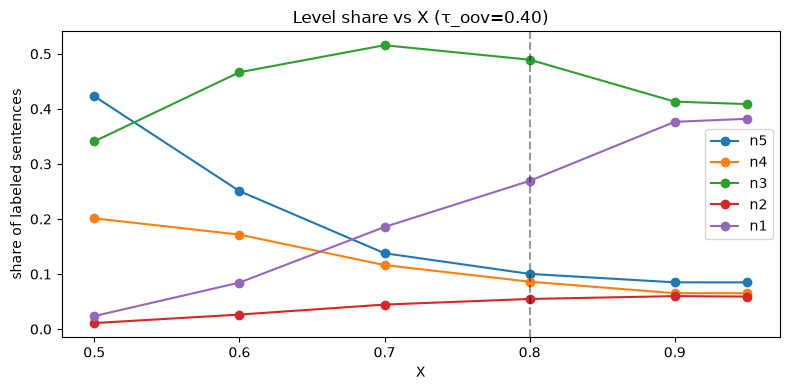

In [5]:
TAU = 0.40
rows = []
for X in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    lab = weak_label(TAU, X)
    kept = lab[lab >= 0]
    row = {"X": X, "abstain": f"{(lab == -1).mean():.1%}"}
    for i, l in enumerate(LEVELS):
        row[l] = f"{(kept == i).mean():.1%}"
    rows.append(row)
sweep = pd.DataFrame(rows).set_index("X")
print(sweep)

fig, ax = plt.subplots(figsize=(8, 4))
Xs = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
for i, l in enumerate(LEVELS):
    share = [( weak_label(TAU, X)[weak_label(TAU, X) >= 0] == i).mean() for X in Xs]
    ax.plot(Xs, share, marker="o", label=l)
ax.axvline(0.80, color="k", ls="--", alpha=.4)
ax.set(title="Level share vs X (τ_oov=0.40)", xlabel="X", ylabel="share of labeled sentences")
ax.legend(); plt.tight_layout(); plt.show()

### Decision — `X = 0.80`
"The sentence's level is where you can read **80%** of its content words" — a reading-comprehension
honest reading that tolerates a ~20% harder tail without letting one rare word define the whole
sentence. `X ≥ 0.9` over-weights that rare tail and inflates N1; `X ≤ 0.6` collapses toward N5/N3.

**Finding — the skew is toward N3, not the easy-skew the roadmap expected.** At (0.40, 0.80) N3 is
~49%. Mechanism: the Tanos lists are wildly uneven — N5=432, N4=452, **N3=1406, N2=1337, N1=2688** —
so most sentences accumulate coverage into the large mid/hard lists and cross `X` at N3. This is a
**label-prior artifact of list size, not ground-truth difficulty.**

**Carry-forward (v1.1 rebalancing):** don't train the classifier on the raw prior. Options to decide
then — class-weighted loss, resampling to a target prior, or coverage normalized by list size. The
weak label is a usable teacher signal, but its marginal is not the real difficulty distribution.

## 3. Abstention + final class balance at the decided thresholds `(τ_oov=0.40, X=0.80)`

abstention rate: 20.1%
labeled sentences: 198,751 / 248,802
  n5:  19,942  (10.0%)
  n4:  17,129  (8.6%)
  n3:  97,265  (48.9%)
  n2:  10,892  (5.5%)
  n1:  53,523  (26.9%)


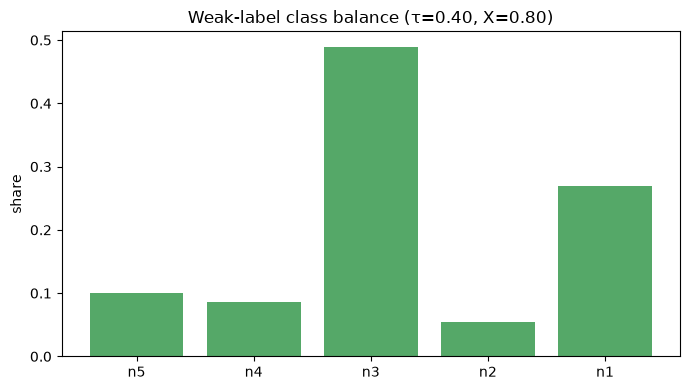

materialized labeled dataset (τ=0.40, X=0.80) -> weak_labels_labeled.parquet  (198,751 labeled, 50,051 abstain)


In [6]:
lab = weak_label(0.40, 0.80)
kept = lab[lab >= 0]
print(f"abstention rate: {(lab == -1).mean():.1%}")
print(f"labeled sentences: {len(kept):,} / {len(df):,}")
for i, l in enumerate(LEVELS):
    print(f"  {l}: {(kept == i).sum():>7,}  ({(kept == i).mean():.1%})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(LEVELS, [(kept == i).mean() for i in range(5)], color="#55A868")
ax.set(title="Weak-label class balance (τ=0.40, X=0.80)", ylabel="share")
plt.tight_layout(); plt.show()

labeled = df.assign(weak_label=lab)
labeled.to_parquet("../data/jlpt/weak_labels_labeled.parquet", index=False)
print(f"materialized labeled dataset (τ=0.40, X=0.80) -> "
      f"weak_labels_labeled.parquet  ({(lab >= 0).sum():,} labeled, {(lab == -1).sum():,} abstain)")

## 4. Label-quality spot-check — **product gate** (spec §7)

Because this labeling function ships with no BERT to clean it, quality is a release criterion, not a
sanity check. Sample **N5/N4-labeled** sentences (the band where a human labeler is reliable) into a
CSV for judgment. This notebook builds the harness and states the criterion; the **human pass is
filled by hand** — no agreement number is invented here.

**Accept criterion (decide before looking):**
- **≥ 85%** weak-label vs human agreement on the N5/N4 spot-check band, **and**
- abstention **≤ ~25%** (met: ≈20% at τ_oov=0.40, see §3).

**Fallback if not met:** relax the §4 lookup keying to `(lemma, reading)` without POS, or narrow the
shipped range to the bands that clear the bar.

In [7]:
sample = df[np.isin(lab, [0, 1])].copy()
sample["weak_label"] = [LEVELS[i] for i in lab[np.isin(lab, [0, 1])]]
sample = sample.sample(60, random_state=7)[["sentence_id", "text", "oov_rate", "weak_label"]]
sample["human_label"] = ""
sample["agree"] = ""
out = "../data/jlpt/spotcheck_n5n4.csv"
sample.to_csv(out, index=False)
print(f"wrote {len(sample)} sentences for human review -> {out}")
sample.head(8)

wrote 60 sentences for human review -> ../data/jlpt/spotcheck_n5n4.csv


,sentence_id,text,oov_rate,weak_label,human_label,agree
240396,12443690,あの子、知ってる？,0.333333,n4,,
96372,184456,学校に遅れるな。,0.000000,n4,,
73270,159026,私はヒロコと湖へ泳ぎに行った。,0.250000,n4,,
35897,109884,彼は一日中ベッドで寝てばかりいた。,0.400000,n5,,
63140,148634,手をあげろ！,0.000000,n5,,
146203,235489,２時間も待たされた。,0.333333,n5,,
181586,5568080,君は弱いな。,0.000000,n5,,
57717,143068,政府は別の歳入源を探さなければいけない、と彼は主張している。,0.285714,n4,,


## Findings note (carry-forward)

1. **`τ_oov = 0.40`** — gate set just below the 0.5 short-sentence OOV spike; above it, sentences are
   genuinely exotic or too short to judge. Abstention ≈ 20% is the honest cost.
2. **`X = 0.80`** — sentence level = 80% content-word coverage; tolerates a hard tail without one
   rare word dominating.
3. **Class balance skews to N3 (~49%), not easy** — an artifact of uneven Tanos list sizes
   (N3/N2/N1 lists are 3–6× the N5/N4 lists), **not** ground-truth difficulty. v1.1 must rebalance
   (class weights / resampling / size-normalized coverage) rather than train on the raw prior.
4. **Short-sentence noise** — OOV rate is unreliable when the vocab frame is tiny; add an
   `n_content ≥ 3` precondition to the gate in v1.1.
5. **Label quality** is a **product gate**, not a data check: N5/N4 spot-check written to
   `spotcheck_n5n4.csv`; accept at ≥85% agreement, else relax lookup keying or narrow the range.
   Human pass pending (Pedro's N5/N4 judgment).

These decisions feed both the shipped v1 vocab-difficulty estimator and the post-launch BERT.